# SFLS: Shape from Laplacian and Shading

In [1]:
import os
import sys
import torch
import torch.optim as optim
import torch.nn.functional as F
import tqdm
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from scipy.optimize import minimize
import plotly.graph_objects as go
import heapq
from torch.utils.tensorboard import SummaryWriter 
#%matplotlib widget
workspace_path = os.path.dirname(os.path.dirname(os.path.abspath("__file__")))
print(workspace_path)
sys.path.append(workspace_path)

from lib.utils_sim import *

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

/path/to/shape-from-heat-conduction-and-shading


### Papameter

In [2]:
sim_params = {
    'sim_width'  : 128,
    'sim_height' : 128,
    'obj_name' : 'igea-60kf', #'igea-60kf', #'concave-25', #'wineglass', #bunny-cut', #'bunny-15k', 'Sphere'
    'obj_zdist': 100,
    'theta_s': 20.0, # 0<theta<180 (pi)
    'phi_s'  : 40.0, # 0<phi<360 (2pi)
    }
width  = sim_params['sim_width']
height = sim_params['sim_height']

In [3]:
sim_params = {
    'sim_width'  : 128,
    'sim_height' : 128,
    'obj_name' : 'armadillo', #'armadillo', #'spot_triangulated', #'bunny',#'bunny-15k-r'# 'concave_wave',
    'obj_zdist': 100,
    'theta_s': 20,
    'phi_s'  :  40,
    'candidates' : 15,
    'noise' : 0.2,
    }
width  = sim_params['sim_width']
height = sim_params['sim_height']

In [4]:
if sim_params['obj_name'] is not None:
    camera_mesh_name = f"{sim_params['obj_name']}_camera_{width}x{height}_{sim_params['obj_zdist']}"
    camera_mesh_path = Path(workspace_path) / f"objs/{camera_mesh_name}.obj"
    
    # if not camera_mesh_path.exists():
    verts_np, faces_np, mask_flat = construct_camera_mesh(sim_params['obj_name'], width, height, sim_params['obj_zdist'], return_mask=True)
    mask2d = mask_flat.reshape(height, width)
    
    # Load camera mesh
    verts_np, faces_np = get_vf_for_obj(camera_mesh_name, norm=False)
    
else:
    # define triangular mesh with simple geometry
    verts_np, faces_np, ii, jj = create_reg_tri_mesh_from_camera(width, height)
    verts_np[:, 2] = -(verts_np[:, 0]**2 + verts_np[:, 1]**2)
    mask = np.zeros(verts_np.shape[0])

pixel_pitch = verts_np[1, 0] - verts_np[0, 0]

# create Trimesh object
mesh = trimesh.Trimesh(vertices=verts_np, faces=faces_np)

Loaded mesh from /path/to/shape-from-heat-conduction-and-shading/objs/armadillo.obj
Scaled mesh to be within coords: Min: [-0.70758428 -1.         -0.67665088] and Max: [0.76366172 0.75263124 0.66018646]
Constructed a camera mesh for armadillo and saved it for future reuse at /path/to/shape-from-heat-conduction-and-shading/objs/armadillo_camera_128x128_100.obj.
Loaded mesh from /path/to/shape-from-heat-conduction-and-shading/objs/armadillo_camera_128x128_100.obj


### Construct / Load ground truth Obj mesh

NOTE; should check andmake it clear

In [5]:
# if sim_params['obj_name'] is not None:
#     camera_mesh_path = Path(workspace_path) / "objs" / f"{sim_params['obj_name']}_v2.obj" # first time v3, after v2
#     if not camera_mesh_path.exists():
#         construct_camera_mesh(sim_params['obj_name'],
#                               width, height,
#                               sim_params['obj_zdist'])
#     verts_np, faces_np = get_vf_for_obj(sim_params['obj_name'], norm=False)

# pixel_pitch = verts_np[1, 0] - verts_np[0, 0]
# # create Trimesh object
# mesh = trimesh.Trimesh(vertices=verts_np, faces=faces_np)

### Ground Truth normal, pq

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-11.185271062540778..12.068841464236812].


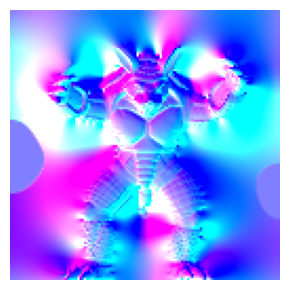

In [6]:
# Finite differencial nomals ()
gtnormals_np = compute_finite_difference_normals(verts_np, width, height, "fwd")
# Get p,q (normalized by nz)
gtnormals_pq_np = gtnormals_np / gtnormals_np[:, 2:3]
p_gt = gtnormals_pq_np[:, 0]
q_gt = gtnormals_pq_np[:, 1]

# Optional (check normal map)
normal_map = gtnormals_pq_np.reshape((height, width, 3))
normal_map = (normal_map + 1) / 2
plt.figure(figsize=(3, 3))
plt.imshow(normal_map, origin='lower')
plt.axis("off")
plt.tight_layout()
plt.show()

### Set GT Source Direction and Shading

ps_gt: 0.2788, qs_gt: 0.2340


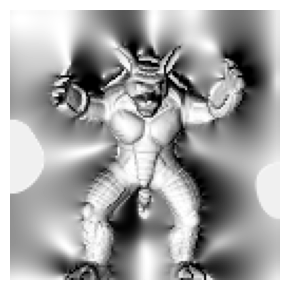

In [7]:
# Set Spherical coords. (theta, phi)
theta_s_gt = np.deg2rad(sim_params['theta_s'])
phi_s_gt   = np.deg2rad(sim_params['phi_s'])
sx_gt = math.sin(theta_s_gt) * math.cos(phi_s_gt)
sy_gt = math.sin(theta_s_gt) * math.sin(phi_s_gt)
sz_gt = math.cos(theta_s_gt)
ps_gt = sx_gt / sz_gt
qs_gt = sy_gt / sz_gt
print(f"ps_gt: {ps_gt:.4f}, qs_gt: {qs_gt:.4f}")

s_vec_gt = np.array([ps_gt, qs_gt, 1.0], dtype=np.float64)
s_norm = s_vec_gt / np.linalg.norm(s_vec_gt)
s_vec_gt_torch = torch.from_numpy(s_vec_gt).float().to(device)
s_norm_torch = s_vec_gt_torch / s_vec_gt_torch.norm()

eta_gt_1d = compute_shading_value(p_gt, q_gt, ps_gt, qs_gt)
eta_gt = eta_gt_1d.reshape((height, width))

plt.figure(figsize=(3,3))
plt.imshow(eta_gt, cmap='gray', origin='lower')
plt.axis("off")
plt.tight_layout()
plt.show()

### Set GT $\Delta$

In [8]:
vertex_cotan_laplacians = cotan_laplacians_from_pq_np(gtnormals_pq_np, width, height)

### Set GT t value

In [9]:
# p,q -> x,y,z - numpy(p,q,-1)
def pq_to_unit_vector(p, q):
    denom = -1.0 / np.sqrt(p**2 + q**2 + 1.0)
    nx = p * denom
    ny = q * denom
    nz = 1 * denom
    return np.array([nx, ny, nz])


In [10]:
# p,q to t
def unit_vector_to_t(unit_vector, eta, s_vec):
    s_norm = s_vec / np.linalg.norm(s_vec)
    R = rotation_matrix_z_to_vec(s_norm)
    # Project the unit vector onto the plane orthogonal to the reference vector
    projection = unit_vector - eta * s_norm
    projection /= np.sqrt(1-eta**2)

    # Transform projection to the standard coordinate system
    # where s_norm becomes z-axis and {u,v} become {x,y} axes
    transformed_proj = R.T @ projection
    
    # Compute azimuthal angle in the XY plane
    t = math.atan2(transformed_proj[1], transformed_proj[0])
    
    # Normalize t to the range [0, 2π)
    if t < 0:
        t += 2 * np.pi
    return t

In [11]:
# eta_1d_torch = torch.from_numpy(eta_gt_1d).float().to(device)
# s_vec_gt_torch = torch.from_numpy(s_vec_gt).float().to(device)
# x_gt, y_gt, z_gt = pq_to_unit_vector(p_gt, q_gt)
# s_vec_gt = np.array([ps_gt, qs_gt, 1.0], dtype=np.float64)
# t_list = [unit_vector_to_t(np.array([x_gt[i], y_gt[i], z_gt[i]]), eta_gt_1d, s_vec_gt)
#           for i in range(x_gt.shape[0])]
# t_gt = np.array(t_list)

## 1. Initial Source Direction Estimation

- Get Near-Planar Patches
- Planar Initialization
- Sign correction with arbitrary ps, qs
- Given a subset of planar p,q, estimate initial ps, qs

### Get Near-Planar Patches

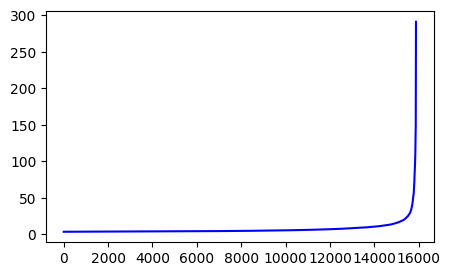

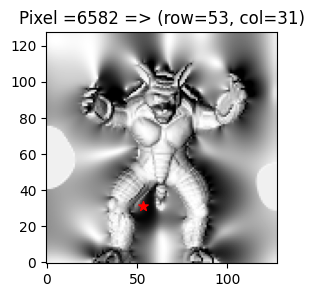

In [12]:
sorted_idx, sorted_L = find_flat_regions(vertex_cotan_laplacians)

# Visualize
i = sorted_idx[0]
row_idx = (i // (width -2)) + 1
col_idx = (i %  (width -2)) + 1
plt.figure(figsize=(3,3))
plt.scatter(row_idx, col_idx, color="red", marker="*", s=50, label="Target Pixel")
plt.title(f"Pixel ={i} => (row={row_idx}, col={col_idx})")
plt.imshow(eta_gt, cmap='gray', origin='lower')
plt.show()

### Planar Initialization

In [13]:

def compute_x0_from_w(w, x0_prev):
    A = (w[0] + w[3]) / 2.0
    B = (w[1] + w[4]) / 2.0
    C = (w[2] + w[5]) / 2.0

    if np.abs(C) == 0:
        # either p or q must be zero. 
        # assert A**2 - 1 >= 0 and B**2 - 1 >= 0
        if A**2 - 1 >= 0 and B**2 - 1 >= 0:
            p = np.sqrt(A**2 - 1)
            q = np.sqrt(B**2 - 1)
            # cannot recover scale when C = 0
            scale = np.nan
        else:
            p = 0
            q = 0
            scale = 1
    else:
        L = (A-B)/C
        
        x1 = (L + np.sqrt(L**2 + 4)) / 2
        x2 = (L - np.sqrt(L**2 + 4)) / 2

        solns = []
        if x1 / (x1 + 1 + B/C) <= 0:
            q = np.sqrt(-x1/(x1+1+B/C))
            p = q / x1
            solns.append((p, q))
        
        if x2 / (x2 + 1 + B/C) <= 0:
            q = np.sqrt(-x2/(x2+1+B/C))
            p = q / x2
            solns.append((p, q))

        if len(solns) > 1:
            print(f"Found multiple solutions: {len(solns)}")
        elif len(solns) == 0:
            x0 = np.random.uniform(-1, 1, 8)
            scale = 1 # np.nan
            return x0, scale
            # raise RuntimeError(f"Did not find any valid initializations for weights {w}")
        
        p, q = solns[0]

        scale_A = A / ((p * (p+q) + 1) / np.sqrt(1 + p**2 + q**2))
        scale_B = B / ((q * (p+q) + 1) / np.sqrt(1 + p**2 + q**2))
        scale = 0.5 * (scale_A + scale_B)
    
    x0_new = np.array([p, q, q, p, p, q, q, p]) 

    # check if sign must be flipped
    max_val_pos = np.abs(x0_prev).argmax()
    if np.sign(x0_prev[max_val_pos]) * np.sign(x0_new[max_val_pos]) < 0:
        x0_new = -x0_new

    x0 = x0_prev.copy()
    x0[x0_prev == 0] = x0_new[x0_prev == 0]

    return x0, scale

In [14]:
def extract_candidates(sorted_idx, sorted_L, TOP_K=None):
    x0_prev = np.zeros(8, dtype=float)
    candidates = []
    count = min(TOP_K, len(sorted_idx))

    for rank in range(count):
        pix_id = sorted_idx[rank]
        w_vals = sorted_L[rank]

        x0, _ = compute_x0_from_w(w_vals, x0_prev)
        p = x0[4]
        q = x0[5]
        
        candidates.append((pix_id, p, q, p, q, p, q, p, q))
    return candidates

all_candidates = extract_candidates(sorted_idx, sorted_L, TOP_K=20)

In [15]:
# Set values for pq_array and eta_array
pq_list = []
eta_list = []

for (pix_id, p, q, p, q, p, q, p, q) in all_candidates:
    row_idx = (pix_id // (width -2)) + 1
    col_idx = (pix_id %  (width -2)) + 1
    
    eta_val = eta_gt[row_idx, col_idx]
    pq_list.append([p, q])
    eta_list.append(eta_val)

pq_array = np.array(pq_list, dtype=np.float64)   # shape (N,2)
eta_array = np.array(eta_list, dtype=np.float64) # shape (N,)

### Sign Correction with Arbitrary s

- Given arbitrary ps and qs, compute eta for both signs(+/-). Then determine the correct sign by comparing the computed eta with the observed eta, using the absolute difference error. Because, the correct direction of s must minimize the error and thus satisfies the observed eta.

In [16]:
fixed_signs, best_err = correct_signs_light(pq_array, eta_array, n_trials=50000, random_seed=42)

print(f"Final sign array: {fixed_signs}")
print(f"Total error: {best_err:.3f}")

Final sign array: [ 1 -1  1  1  1  1 -1  1  1  1 -1 -1  1 -1  1  1 -1  1  1  1]
Total error: 0.108


In [17]:
# Update all_candidates with fixed signs
all_candidates_fixed = []
for i, candidate in enumerate(all_candidates):
    pix_id, p, q, p_a, q_a, p_b, q_b, p_f, q_f = candidate
    sign = fixed_signs[i]
    
    candidate_fixed = (pix_id,
                       p   * sign, q   * sign,
                       p_a * sign, q_a * sign,
                       p_b * sign, q_b * sign,
                       p_f * sign, q_f * sign)
    
    all_candidates_fixed.append(candidate_fixed)

#### Visualize (Sign correction)

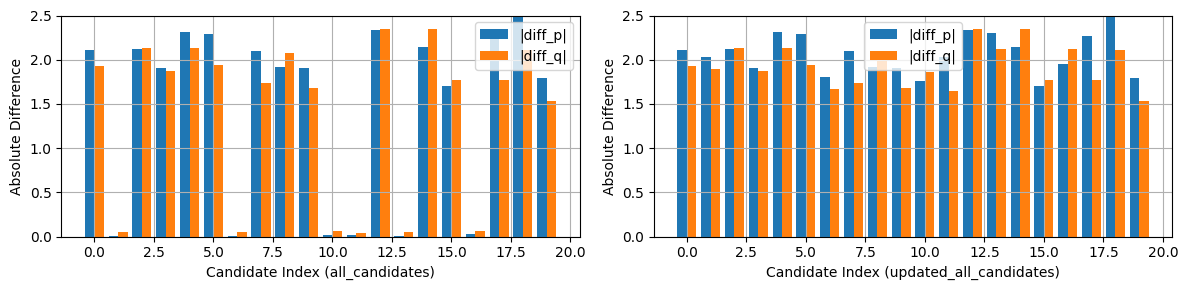

In [18]:
# Collect indices and absolute differences for all_candidates
pixel_indices_all = []   # Indices of each candidate
abs_diffs_p_all = []     # Absolute differences for p
abs_diffs_q_all = []     # Absolute differences for q

for i, candidate in enumerate(all_candidates):
    # candidate[0]: Local pixel ID
    i_v = candidate[0]
    # Compute row and column based on 126 as reference (adjust as needed)
    row = (i_v // (width -2)) + 1
    col = (i_v %  (width -2)) + 1
    # Compute global index (image size: height x width)
    i_v_glb = np.ravel_multi_index((row, col), dims=(height, width))
    # Assume gtnormals_pq_np has shape (total_pixels, 3) with (p, q, ?)
    gt_p, gt_q, _ = gtnormals_pq_np[i_v_glb]
    cand_p = candidate[1]
    cand_q = candidate[2]
    diff_p = cand_p - gt_p
    diff_q = cand_q - gt_q
    pixel_indices_all.append(i)  # Simply assign indices in order of candidates
    abs_diffs_p_all.append(abs(diff_p))
    abs_diffs_q_all.append(abs(diff_q))

# Collect indices and absolute differences
pixel_indices_updated = []   # Indices of each candidate
abs_diffs_p_updated = []     # Absolute differences for p
abs_diffs_q_updated = []     # Absolute differences for q

for i, candidate in enumerate(all_candidates_fixed):
    i_v = candidate[0]
    row = (i_v // (width -2)) + 1
    col = (i_v %  (width -2)) + 1
    i_v_glb = np.ravel_multi_index((row, col), dims=(height, width))
    gt_p, gt_q, _ = gtnormals_pq_np[i_v_glb]
    cand_p = candidate[1]
    cand_q = candidate[2]
    diff_p = cand_p - gt_p
    diff_q = cand_q - gt_q
    pixel_indices_updated.append(i)
    abs_diffs_p_updated.append(abs(diff_p))
    abs_diffs_q_updated.append(abs(diff_q))

# Plot graphs side by side
bar_width = 0.4

# Convert indices to numpy arrays
x_all = np.array(pixel_indices_all)
x_updated = np.array(pixel_indices_updated)
# Plot graphs side by side using plt
plt.figure(figsize=(12, 3))

# Left: Graph for all_candidates
plt.subplot(1, 2, 1)
plt.bar(x_all - bar_width/2, abs_diffs_p_all, width=bar_width, label='|diff_p|')
plt.bar(x_all + bar_width/2, abs_diffs_q_all, width=bar_width, label='|diff_q|')
plt.xlabel("Candidate Index (all_candidates)")
plt.ylabel("Absolute Difference")
plt.legend()
plt.ylim(0, 2.5)
plt.grid(True)

# Right: Graph for updated_all_candidates
plt.subplot(1, 2, 2)
plt.bar(x_updated - bar_width/2, abs_diffs_p_updated, width=bar_width, label='|diff_p|')
plt.bar(x_updated + bar_width/2, abs_diffs_q_updated, width=bar_width, label='|diff_q|')
plt.xlabel("Candidate Index (updated_all_candidates)")
plt.ylabel("Absolute Difference")
plt.legend()
plt.ylim(0, 2.5)
plt.grid(True)

plt.tight_layout()
plt.show()

### Reverse Photometric Stereo (Initial Source Estimation)
- Get Initial Estimated Source Direction (ps_init, qs_init).

In [19]:
# Set values for pq_array and eta_array
pq_list_fixed = []
eta_list_fixed = []

for (pix_id, p, q, p, q, p, q, p, q) in all_candidates_fixed:
    row_idx = (pix_id // (width -2)) + 1
    col_idx = (pix_id %  (width -2)) + 1
    
    eta_val = eta_gt[row_idx, col_idx]
    pq_list_fixed.append([p, q])
    eta_list_fixed.append(eta_val)

pq_array_fixed = np.array(pq_list_fixed, dtype=np.float64)   # shape (N,2)
eta_array_fixed = np.array(eta_list_fixed, dtype=np.float64) # shape (N,)

ps_fixed, qs_fixed, residual_gt = reverse_photometric_stereo_ransac(pq_array_fixed,
                                                                    eta_array_fixed,
                                                                    n_iter=50000,
                                                                    subset_size=5)

print(f"Ground truth  : ps, qs = {ps_gt:.3f}, {qs_gt:.3f}")
print(f"After  refined: ps, qs = {ps_fixed:.3f}, {qs_fixed:.3f}")
print(f"Residual: {residual_gt}")

Ground truth  : ps, qs = 0.279, 0.234
After  refined: ps, qs = -0.174, -0.203
Residual: 9.85347700938079e-12


#### Visualize initial s (compared to GT)

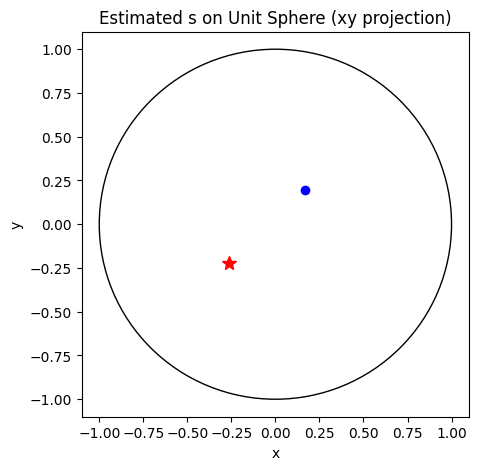

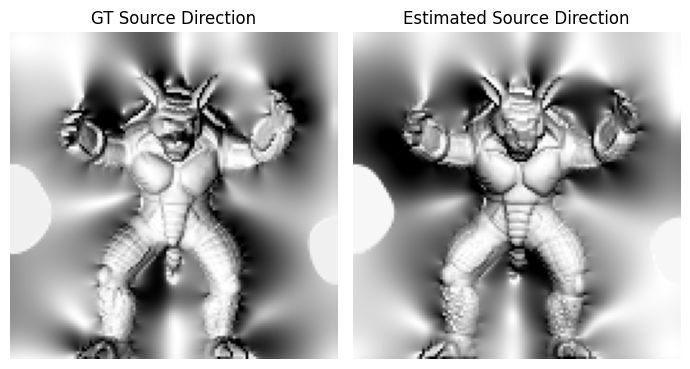

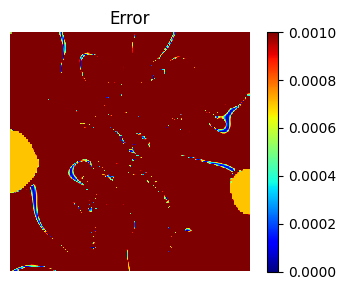

In [20]:
# Convert ground truth and estimated values to unit vectors
sx_gt, sy_gt, sz_gt = pq_to_unit_vector(ps_gt, qs_gt)
sx_est, sy_est, sz_est = pq_to_unit_vector(ps_fixed, qs_fixed)

plt.figure(figsize=(5,5))
plt.scatter(sx_est, sy_est, color='blue')
plt.plot(sx_gt, sy_gt, marker='*', markersize=10, color='red', linestyle='None')

circle = plt.Circle((0, 0), 1.0, fill=False, color='black')
plt.gca().add_patch(circle)

plt.xlim([-1.1, 1.1])
plt.ylim([-1.1, 1.1])
plt.xlabel("x")
plt.ylabel("y")
plt.title("Estimated s on Unit Sphere (xy projection)")
plt.show()

# Shading image
eta_est_1d_est = compute_shading_value(p_gt, q_gt, ps_fixed, qs_fixed)
eta_est = eta_est_1d_est.reshape((height, width))
error_image = (eta_gt - eta_est)**2

plt.figure(figsize=(7,5))
plt.subplot(1,2,1)
plt.title("GT Source Direction")
plt.imshow(eta_gt, cmap='gray', origin='lower')
plt.axis("off")
plt.subplot(1,2,2)
plt.title("Estimated Source Direction")
plt.imshow(eta_est, cmap='gray', origin='lower')
plt.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(4,3))
plt.title("Error")
plt.imshow(error_image, cmap='jet', vmin=0, vmax=0.001, origin='lower')
plt.axis("off")
plt.colorbar()
plt.tight_layout()
plt.show()

## 2. Refinement given Initial Source Direction

- Refine the planar pixel of p,q minimizing laplacian cost function.
- Given refined p,q, re-estimate source direciton by using reverse photometric stereo.

### Objective Function

$$L = \left\| \Delta_{\text{gt}} - {\hat{\Delta}} \right\|_2

In [21]:
def obj_function(x,
                 idx_i, idx_a, idx_b, idx_d, idx_e, idx_f,
                 i_v,
                 L,
                 width, height):
    
    p_i, q_i, p_a, q_a, p_b, q_b, p_f, q_f = x
    p_d = p_i + q_b - q_i
    p_e = p_f + q_a - q_f

    # Laplacian error
    pq_modified = np.zeros((height*width, 2), dtype=np.float64)
    pq_modified[idx_i, 0] = p_i
    pq_modified[idx_i, 1] = q_i
    pq_modified[idx_a, 1] = q_a
    pq_modified[idx_b, 1] = q_b
    pq_modified[idx_d, 0] = p_d
    pq_modified[idx_e, 0] = p_e
    pq_modified[idx_f, 0] = p_f
    pq_modified[idx_f, 1] = q_f
    
    lap_hat = cotan_laplacians_from_pq_np(pq_modified, width, height)
    diff_lap = L[i_v] - lap_hat[i_v]
    E_lap = np.mean(diff_lap**2)

    return E_lap

In [22]:
def run_refinement(all_candidates, L, width, height, ind_v, ind_a, ind_b, ind_d, ind_e, ind_f):
    
    results_refined = []

    for _, candidate in enumerate(all_candidates):
        pix_id, p_i, q_i, p_a, q_a, p_b, q_b, p_f, q_f = candidate

        row = (pix_id // (width -2)) + 1
        col = (pix_id %  (width -2)) + 1
        idx_i = np.ravel_multi_index((row, col), dims=(height, width))

        i_v = np.where(ind_v == idx_i)[0][0]
        idx_a = ind_a[i_v]
        idx_b = ind_b[i_v]
        idx_d = ind_d[i_v]
        idx_e = ind_e[i_v]
        idx_f = ind_f[i_v]

        x0 = np.array([p_i, q_i, p_a, q_a,
                       p_b, q_b, p_f, q_f], dtype=np.float64)
        
        def wrapped_objective(x):
            return obj_function(x, idx_i, idx_a, idx_b, idx_d, idx_e, idx_f, i_v, L, width, height)
        
        res = minimize(wrapped_objective,
                       x0,
                       method="L-BFGS-B",
                       options={"ftol": 1e-16})
        best_x = res.x

        # Results
        p_i, q_i, p_a, q_a, p_b, q_b, p_f, q_f = best_x
        results_refined.append((pix_id, p_i, q_i, p_a, q_a, p_b, q_b, p_f, q_f))

    return results_refined

In [23]:
def compute_total_obj_function(all_candidates, L, width, height, ind_v, ind_a, ind_b, ind_d, ind_e, ind_f):

    total_cost = 0.0
    for (pix_id, p_i, q_i, p_a, q_a, p_b, q_b, p_f, q_f) in all_candidates:
        row = (pix_id // (width-2)) + 1
        col = (pix_id %  (width-2)) + 1
        idx_i = np.ravel_multi_index((row, col), dims=(height, width))

        i_v = np.where(ind_v == idx_i)[0][0]
        idx_a = ind_a[i_v]
        idx_b = ind_b[i_v]
        idx_d = ind_d[i_v]
        idx_e = ind_e[i_v]
        idx_f = ind_f[i_v]

        x = np.array([p_i, q_i, p_a, q_a,
                      p_b, q_b, p_f, q_f], dtype=np.float64)

        pix_obj = obj_function(x, idx_i, idx_a, idx_b, idx_e, idx_d, idx_f, i_v, L, width, height)
        total_cost += pix_obj

    return total_cost

In [24]:
def main_refinement(all_candidates, width, height, L, ind_v, ind_a, ind_b, ind_d, ind_e, ind_f, max_iter=None, tol=None):

    # ============== cost_prev =================
    cost_prev = compute_total_obj_function(all_candidates, L, width, height, ind_v, ind_a, ind_b, ind_d, ind_e, ind_f)
    print(f"Initial cost = {cost_prev:.6f}")

    for iter in range(1, max_iter+1):
        # ======================= refine p,q ========================
        results_refined = run_refinement(all_candidates, L, width, height, ind_v, ind_a, ind_b, ind_d, ind_e, ind_f)
        all_candidates = results_refined
        
        # ============== cost_new =================
        cost_new = compute_total_obj_function(all_candidates, L, width, height, ind_v, ind_a, ind_b, ind_d, ind_e, ind_f)
        print(f"Cost new = {cost_new:.10f}")
        diff_cost = abs(cost_new - cost_prev)

        # ============== update =================
        cost_prev = cost_new
        if diff_cost < tol:
            break

    return all_candidates

In [25]:
ind_v, ind_a, ind_b, ind_c, ind_d, ind_e, ind_f, ind_g, ind_h = get_ngbr_indices(width, height)

all_candidates_refined = main_refinement(all_candidates_fixed,
                                         width, height,
                                         vertex_cotan_laplacians,
                                         ind_v, ind_a, ind_b, ind_d, ind_e, ind_f,
                                         max_iter=10,
                                         tol=1e-16)
print("Refinement Done")

Initial cost = 0.010033


Cost new = 0.0140258099
Cost new = 0.0140258099
Refinement Done


#### Update Source direction (RPS method)

In [26]:
pq_list_refined = []
eta_list_refined = []

for (pix_id, p, q, p_a, q_a, p_b, q_b, p_f, q_f) in all_candidates_refined:
    row = (pix_id // (width -2)) + 1
    col = (pix_id %  (width -2)) + 1

    eta_val = eta_gt[row, col]
    pq_list_refined.append([p, q])
    eta_list_refined.append(eta_val)

pq_array_refined = np.array(pq_list_refined, dtype=np.float64)   # shape (N,2)
eta_array_refined = np.array(eta_list_refined, dtype=np.float64) # shape (N,)

# Perform reverse photometric stereo using ground truth values # NOTE: This is without RANSAC
# ps_final, qs_final, residual_gt = reverse_photometric_stereo(pq_array_refined, eta_array_refined)

# print(f"Ground truth  : ps, qs = {ps_gt:.3f}, {qs_gt:.3f}")
# print(f"After  refined: ps, qs = {ps_final:.3f}, {qs_final:.3f}")
# print(f"Residual: {residual_gt:.6f}")

# Perform reverse photometric stereo using ground truth values
ps_final, qs_final, residual_gt = reverse_photometric_stereo_ransac(pq_array_refined,
                                                                    eta_array_refined,
                                                                    n_iter=50000,
                                                                    subset_size=5)
print(f"Ground truth  : ps, qs = {ps_gt:.3f}, {qs_gt:.3f}")
print(f"After  refined: ps, qs = {ps_final:.3f}, {qs_final:.3f}")
print(f"Residual: {residual_gt}")

Ground truth  : ps, qs = 0.279, 0.234
After  refined: ps, qs = -0.297, -0.229
Residual: 2.533544184939131e-11


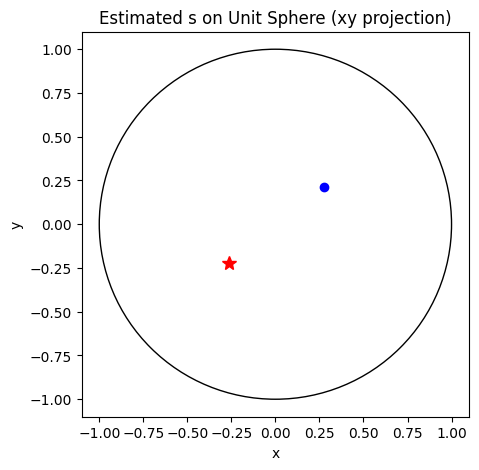

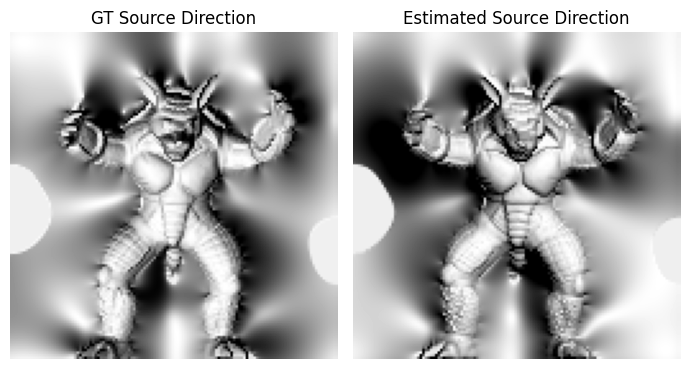

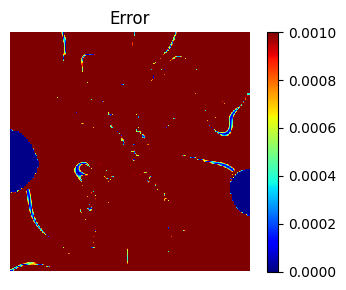

In [27]:
# Convert ground truth and estimated values to unit vectors
sx_gt, sy_gt, sz_gt = pq_to_unit_vector(ps_gt, qs_gt)
sx_est, sy_est, sz_est = pq_to_unit_vector(ps_final, qs_final)

plt.figure(figsize=(5,5))
plt.scatter(sx_est, sy_est, color='blue')
plt.plot(sx_gt, sy_gt, marker='*', markersize=10, color='red', linestyle='None')

circle = plt.Circle((0, 0), 1.0, fill=False, color='black')
plt.gca().add_patch(circle)

plt.xlim([-1.1, 1.1])
plt.ylim([-1.1, 1.1])
plt.xlabel("x")
plt.ylabel("y")
plt.title("Estimated s on Unit Sphere (xy projection)")
plt.show()


# Shading image
eta_est_1d_est = compute_shading_value(p_gt, q_gt, ps_final, qs_final)
eta_est = eta_est_1d_est.reshape((height, width))
error_image = (eta_gt - eta_est)**2

plt.figure(figsize=(7,5))
plt.subplot(1,2,1)
plt.title("GT Source Direction")
plt.imshow(eta_gt, cmap='gray', origin='lower')
plt.axis("off")
plt.subplot(1,2,2)
plt.title("Estimated Source Direction")
plt.imshow(eta_est, cmap='gray', origin='lower')
plt.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(4,3))
plt.title("Error")
plt.imshow(error_image, cmap='jet', vmin=0, vmax=0.001, origin='lower')
plt.axis("off")
plt.colorbar()
plt.tight_layout()
plt.show()

#### Check result: optional

In [28]:
i_v = all_candidates_refined[0][0]
row = (i_v // (width -2)) + 1
col = (i_v %  (height-2)) + 1
i_v_glb = np.ravel_multi_index((row, col), dims=(height, width))
print("GT Normal (ind_v):", gtnormals_pq_np[ind_v[i_v]])
print("GT Normal (ind_a):", gtnormals_pq_np[ind_a[i_v]])
print("GT Normal (ind_b):", gtnormals_pq_np[ind_b[i_v]])
print("GT Normal (ind_f):", gtnormals_pq_np[ind_f[i_v]])

print("Candidate 1 (pq_v):", all_candidates_refined[0][1], all_candidates_refined[0][2])
print("Candidate 2 (pq_a):", all_candidates_refined[0][3], all_candidates_refined[0][4])
print("Candidate 3 (pq_b):", all_candidates_refined[0][5], all_candidates_refined[0][6])
print("Candidate 4 (pq_f):", all_candidates_refined[0][7], all_candidates_refined[0][8])

GT Normal (ind_v): [ 1.05669239 -0.93728512  1.        ]
GT Normal (ind_a): [ 1.15926463 -1.0472014   1.        ]
GT Normal (ind_b): [ 1.06309352 -1.0380295   1.        ]
GT Normal (ind_f): [ 1.14866802 -0.95117174  1.        ]
Candidate 1 (pq_v): -1.0369419504526116 0.9572746625826785
Candidate 2 (pq_a): -1.0531872214919424 1.0207659147119552
Candidate 3 (pq_b): -1.0531872214919424 0.983581359958009
Candidate 4 (pq_f): -1.0729444128358445 1.0222659993477523


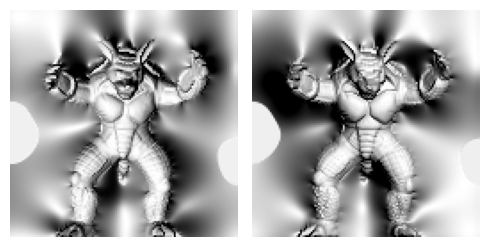

In [29]:
eta_test1 = compute_shading_value(p_gt, q_gt, ps_gt, qs_gt)
eta_test1 = eta_test1.reshape((height, width))
eta_test2 = compute_shading_value(p_gt, q_gt, ps_final, qs_final)
eta_test2 = eta_test2.reshape((height, width))

plt.figure(figsize=(5, 3))
plt.subplot(1, 2, 1)
plt.imshow(eta_test1, cmap='gray', origin='lower')
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(eta_test2, cmap='gray', origin='lower')
plt.axis("off")
plt.tight_layout()
plt.show()

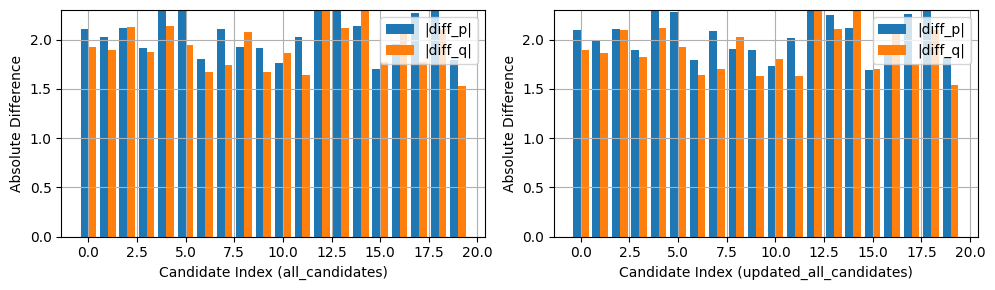

In [30]:
# Collect indices and absolute differences for all_candidates
pixel_indices_all = []   # Indices of each candidate
abs_diffs_p_all = []     # Absolute differences for p
abs_diffs_q_all = []     # Absolute differences for q

for i, candidate in enumerate(all_candidates_fixed):
    # candidate[0]: Local pixel ID
    i_v = candidate[0]
    # Compute row and column based on 126 as reference (adjust as needed)
    row = (i_v // (width -2)) + 1
    col = (i_v %  (width -2)) + 1
    # Compute global index (image size: height x width)
    i_v_glb = np.ravel_multi_index((row, col), dims=(height, width))
    # Assume gtnormals_pq_np has shape (total_pixels, 3) with (p, q, ?)
    gt_p, gt_q, _ = gtnormals_pq_np[i_v_glb]
    cand_p = candidate[1]
    cand_q = candidate[2]
    diff_p = cand_p - gt_p
    diff_q = cand_q - gt_q
    pixel_indices_all.append(i)  # Simply assign indices in order of candidates
    abs_diffs_p_all.append(abs(diff_p))
    abs_diffs_q_all.append(abs(diff_q))

# Collect indices and absolute differences
pixel_indices_updated = []   # Indices of each candidate
abs_diffs_p_updated = []     # Absolute differences for p
abs_diffs_q_updated = []     # Absolute differences for q

for i, candidate in enumerate(all_candidates_refined):
    i_v = candidate[0]
    row = (i_v // (width -2)) + 1
    col = (i_v %  (height-2)) + 1
    i_v_glb = np.ravel_multi_index((row, col), dims=(height, width))
    gt_p, gt_q, _ = gtnormals_pq_np[i_v_glb]
    cand_p = candidate[1]
    cand_q = candidate[2]
    diff_p = cand_p - gt_p
    diff_q = cand_q - gt_q
    pixel_indices_updated.append(i)
    abs_diffs_p_updated.append(abs(diff_p))
    abs_diffs_q_updated.append(abs(diff_q))

# Plot graphs side by side
bar_width = 0.4

# Convert indices to numpy arrays
x_all = np.array(pixel_indices_all)
x_updated = np.array(pixel_indices_updated)
# Plot graphs side by side using plt
plt.figure(figsize=(10, 3))

# Left: Graph for all_candidates
plt.subplot(1, 2, 1)
plt.bar(x_all - bar_width/2, abs_diffs_p_all, width=bar_width, label='|diff_p|')
plt.bar(x_all + bar_width/2, abs_diffs_q_all, width=bar_width, label='|diff_q|')
plt.xlabel("Candidate Index (all_candidates)")
plt.ylabel("Absolute Difference")
plt.legend()
plt.ylim(0, 2.3)
plt.grid(True)

# Right: Graph for updated_all_candidates
plt.subplot(1, 2, 2)
plt.bar(x_updated - bar_width/2, abs_diffs_p_updated, width=bar_width, label='|diff_p|')
plt.bar(x_updated + bar_width/2, abs_diffs_q_updated, width=bar_width, label='|diff_q|')
plt.xlabel("Candidate Index (updated_all_candidates)")
plt.ylabel("Absolute Difference")
plt.legend()
plt.ylim(0, 2.3)
plt.grid(True)

plt.tight_layout()
plt.show()

## Optimization

### Objective Function & Constraints

$$L = \left\| \Delta_{\text{gt}} - {\hat{\Delta}} \right\|_2

In [31]:
def obj_function_t_torch(t_param,
                         idx_target_torch, idx_a_torch, idx_b_torch, idx_d_torch, idx_e_torch, idx_f_torch,
                         eta_1d_torch,
                         s_vec_torch,
                         L_ref,
                         width, height):

    # (1) First, extract t_i, and itsneighbors of t_a, t_b, t_f.
    t_i  = t_param[idx_target_torch]  # shape (N_inner,)
    t_a  = t_param[idx_a_torch]       # shape (N_inner,)
    t_b  = t_param[idx_b_torch]
    t_f  = t_param[idx_f_torch]
    
    # (2) Extract eta
    eta_i = eta_1d_torch[idx_target_torch]  # shape (N_inner,)
    eta_a = eta_1d_torch[idx_a_torch]
    eta_b = eta_1d_torch[idx_b_torch]
    eta_f = eta_1d_torch[idx_f_torch]

    # (3) Calculate p, q (vectorized)
    p_i, q_i = t_to_pq_torch(t_i, eta_i, s_vec_torch)  # shape (N_inner,) each
    p_a, q_a = t_to_pq_torch(t_a, eta_a, s_vec_torch)
    p_b, q_b = t_to_pq_torch(t_b, eta_b, s_vec_torch)
    p_f, q_f = t_to_pq_torch(t_f, eta_f, s_vec_torch)
    p_d = p_i + (q_b - q_i)
    p_e = p_f + (q_a - q_f)

    pq_modified = torch.zeros((height*width, 2), dtype=t_param.dtype, device=t_param.device)
    pq_modified[idx_target_torch, 0] = p_i
    pq_modified[idx_target_torch, 1] = q_i
    #pq_modified[idx_a_torch, 0] = p_a
    pq_modified[idx_a_torch, 1] = q_a
    #pq_modified[idx_b_torch, 0] = p_b
    pq_modified[idx_b_torch, 1] = q_b
    pq_modified[idx_d_torch, 0] = p_d
    pq_modified[idx_e_torch, 0] = p_e
    pq_modified[idx_f_torch, 0] = p_f
    pq_modified[idx_f_torch, 1] = q_f

    lap_hat = cotan_laplacians_from_pq_torch(pq_modified, width, height, device=t_param.device)
    diff = L_ref - lap_hat
    E_lap = torch.mean(diff**2)
    
    return E_lap

In [32]:
# Prepare for PyTorch optimization variables
s_vec = np.array([ps_final, qs_final, 1.0], dtype=np.float64)
#s_vec = np.array([ps_gt, qs_gt, 1.0], dtype=np.float64) # NOTE: This is only for testing
#s_vec_norm = s_vec / np.linalg.norm(s_vec)
s_vec_torch = torch.from_numpy(s_vec).float().to(device)
#s_vec_norm_torch = torch.from_numpy(s_vec_norm).float().to(device)

L_torch = torch.from_numpy(vertex_cotan_laplacians).float().to(device)
eta_1d_torch = torch.from_numpy(eta_gt_1d).float().to(device)
idx_target_torch = torch.tensor(ind_v, dtype=torch.long, device=device)
idx_a_torch      = torch.tensor(ind_a, dtype=torch.long, device=device)
idx_b_torch      = torch.tensor(ind_b, dtype=torch.long, device=device)
idx_d_torch      = torch.tensor(ind_d, dtype=torch.long, device=device)
idx_e_torch      = torch.tensor(ind_e, dtype=torch.long, device=device)
idx_f_torch      = torch.tensor(ind_f, dtype=torch.long, device=device)
N = height * width

#### Params

In [33]:
optimization_params = {'lr': 1e-3,
                       'max_iters': 40000}

### Optimization function for SFS and SFL

In [34]:
def compute_shading_value_torch(p, q, ps, qs):
    denom_n = torch.sqrt(p**2 + q**2 + 1.0)
    denom_s = torch.sqrt(ps**2 + qs**2 + 1.0)
    eta = (p * ps + q * qs + 1.0) / (denom_n * denom_s)
    eta = torch.clamp(eta, min=0.0)
    return eta

def obj_function_torch(p_param, q_param,
                         idx_target_torch, idx_a_torch, idx_b_torch, idx_d_torch, idx_e_torch, idx_f_torch,
                         eta_1d_torch,
                         s_vec_torch,
                         L_ref,
                         width, height):

    # (1) First, extract t_i, and itsneighbors of t_a, t_b, t_f.
    p_i = p_param[idx_target_torch]
    q_i = q_param[idx_target_torch]
    p_a = p_param[idx_a_torch]   
    q_a = q_param[idx_a_torch]   
    p_b = p_param[idx_b_torch]
    q_b = q_param[idx_b_torch]
    p_f = p_param[idx_f_torch]
    q_f = q_param[idx_f_torch]

    p_d = p_i + (q_b - q_i)
    p_e = p_f + (q_a - q_f)

    pq_modified = torch.zeros((height*width, 2), device=p_param.device)
    pq_modified[idx_target_torch, 0] = p_i
    pq_modified[idx_target_torch, 1] = q_i
    pq_modified[idx_a_torch, 0] = p_a
    pq_modified[idx_a_torch, 1] = q_a
    pq_modified[idx_b_torch, 0] = p_b
    pq_modified[idx_b_torch, 1] = q_b
    pq_modified[idx_d_torch, 0] = p_d
    pq_modified[idx_e_torch, 0] = p_e
    pq_modified[idx_f_torch, 0] = p_f
    pq_modified[idx_f_torch, 1] = q_f

    lap_hat = cotan_laplacians_from_pq_torch(pq_modified, width, height, device=p_param.device)
    diff = L_ref - lap_hat
    E_lap = torch.mean(diff**2)
    
    E_sha = 0.0

    # Only 4 neighbors are enough
    eta_center = eta_1d_torch[idx_target_torch]
    shading_val = compute_shading_value_torch(p_i, q_i, s_vec_torch[0], s_vec_torch[1])
    E_sha += (shading_val - eta_center)**2

    eta_a = eta_1d_torch[idx_a_torch]
    shading_val = compute_shading_value_torch(p_a, q_a, s_vec_torch[0], s_vec_torch[1])
    E_sha += (shading_val - eta_a)**2

    eta_b = eta_1d_torch[idx_b_torch]
    shading_val = compute_shading_value_torch(p_b, q_b, s_vec_torch[0], s_vec_torch[1])
    E_sha += (shading_val - eta_b)**2

    eta_f = eta_1d_torch[idx_f_torch]
    shading_val = compute_shading_value_torch(p_f, q_f, s_vec_torch[0], s_vec_torch[1])
    E_sha += (shading_val - eta_f)**2   
    E_sha = E_sha.mean() 

    return E_lap + E_sha 

#### Optimization Function

In [35]:
def optimize_pq(p_init, q_init,
               idx_target_torch, idx_a_torch, idx_b_torch, idx_d_torch, idx_e_torch, idx_f_torch,
               eta_1d_torch,
               s_vec_torch,
               L_torch,
               width, height,
               optimization_params,
               writer_prefix="Case"):

    p_param = torch.nn.Parameter(p_init.clone())
    q_param = torch.nn.Parameter(q_init.clone())
    ps_param = torch.nn.Parameter(torch.randn(1).to(device) * 0.1)
    qs_param = torch.nn.Parameter(torch.randn(1).to(device) * 0.1)    
    optimizer = torch.optim.Adam([p_param, q_param, ps_param, qs_param], lr=optimization_params['lr'])
    prev_loss = None

    pbar = tqdm(range(optimization_params['max_iters']))
    for iter in pbar:
        optimizer.zero_grad()
        # Loss
        s_hat_torch = torch.cat((ps_param, qs_param, torch.ones_like(ps_param)), dim=0)
        #s_hat_torch = s_hat_torch / s_hat_torch.norm(dim=1, keepdim=True)
        loss = obj_function_torch(p_param, q_param,
                                    idx_target_torch, idx_a_torch, idx_b_torch,
                                    idx_d_torch, idx_e_torch, idx_f_torch,
                                    eta_1d_torch, s_hat_torch, L_torch, width, height)
        # Backpropagation
        loss.backward()

        optimizer.step()

        loss_val = loss.item()
        tol = 1e-12
        current_lr = optimizer.param_groups[0]["lr"]
        if iter % 100 == 0:
            pbar.set_description(f"{writer_prefix} iter: {iter} => loss: {loss.item():>7f} lr: {current_lr:>7f}")

        if prev_loss is not None:
            delta = abs(prev_loss - loss_val)
            if delta < tol:
                pbar.set_description(
                    f"{writer_prefix} converged at iter {iter} (Δloss {delta:.2e} < tol {tol})"
                )
                break

        prev_loss = loss_val
    print(ps_param.item(), qs_param.item())
    return p_param, q_param, s_hat_torch


In [36]:
s_vec_torch.shape

torch.Size([3])

#### Main Propagation (Stage 1 and 2)

- Stage 1: Optimize the entire t value; this inclutes local minima.
- Stage 2: Compute t1 and t2 from initial t. Then, optimize both t's.

In [37]:
import time
## Main
# =========================== Stage 1 ==========================
#p_init = torch.nn.Parameter(torch.zeros(N, dtype=torch.float, device=device))
#q_init = torch.nn.Parameter(torch.zeros(N, dtype=torch.float, device=device))
p_init = torch.nn.Parameter(torch.randn(N, device=device) * 1e-3)
q_init = torch.nn.Parameter(torch.randn(N, device=device) * 1e-3)
#ps_init = torch.nn.Parameter(torch.randn(N, device=device) * 1e-3)
#qs_init = torch.nn.Parameter(torch.randn(N, device=device) * 1e-3)
start = time.perf_counter()
p_param, q_param, s_hat_torch = optimize_pq(p_init, q_init,
                          idx_target_torch, idx_a_torch, idx_b_torch, idx_d_torch, idx_e_torch, idx_f_torch,
                          eta_1d_torch,
                          s_vec_torch,
                          L_torch,
                          width, height,
                          optimization_params,
                          writer_prefix="Stage1")
end = time.perf_counter()
print(f"Stage1 elapsed: {end - start:.3f} sec")
# # =========================== Stage 2 =========================== 
# # Set initial t (t1 and t2 from initial t)
# with torch.no_grad():
#     p_1, q_1 = t_to_pq_torch(t_param_init, eta_1d_torch, s_vec_torch)

# t_1_init = pq_to_t_torch( p_1,  q_1, s_vec_torch)
# t_2_init = pq_to_t_torch(-p_1, -q_1, s_vec_torch)

# # Optimize t1 and t2
# t_param_1 = optimize_t(t_1_init,
#                        idx_target_torch, idx_a_torch, idx_b_torch, idx_d_torch, idx_e_torch, idx_f_torch,
#                        eta_1d_torch, s_vec_torch, L_torch,
#                        width, height,
#                        optimization_params,
#                        writer_prefix="Stage2_t1")

# t_param_2 = optimize_t(t_2_init,
#                        idx_target_torch, idx_a_torch, idx_b_torch, idx_d_torch, idx_e_torch, idx_f_torch,
#                        eta_1d_torch, s_vec_torch, L_torch,
#                        width, height,
#                        optimization_params,
#                        writer_prefix="Stage2_t2")

# with torch.no_grad():
#     t_param_1 = t_param_1.reshape(width, height)[1:-1, 1:-1]
#     t_param_2 = t_param_2.reshape(width, height)[1:-1, 1:-1]
#     t_param_1 = t_param_1.flatten()
#     t_param_2 = t_param_2.flatten()

Stage1 converged at iter 24134 (Δloss 0.00e+00 < tol 1e-12):  60%|██████    | 24134/40000 [01:30<00:59, 266.66it/s]

-0.07018548995256424 0.06586896628141403
Stage1 elapsed: 90.505 sec


In [38]:
s_hat_np = s_hat_torch.detach().cpu().numpy()

ps_est = s_hat_np[0]
qs_est = s_hat_np[1]

v_gt = np.array([ps_gt, qs_gt, 1.0])
v_est = np.array([ps_est, qs_est, 1.0])

v_gt_norm = v_gt / np.linalg.norm(v_gt)
v_est_norm = v_est / np.linalg.norm(v_est)

dot_product = np.dot(v_gt_norm, v_est_norm)
dot_product = np.clip(dot_product, -1.0, 1.0)

angle_error_rad = np.arccos(dot_product)
angle_error_deg = np.degrees(angle_error_rad)

print(f"Angular error: {angle_error_deg:.4f} degrees")

Angular error: 21.3397 degrees


#### Stage 3 (Propagation)

- Set the correct t by choosing between t1 and t2, by anchoring on the initially refined pixel.

In [39]:
# def propagate_with_t(t1, t2, neighbor_dict, seed):
#     N = t1.shape[0]
#     t_final = np.zeros(N, dtype=np.float64)
#     visited = np.zeros(N, dtype=bool)

#     # Initialize
#     t_final[seed] = t1[seed]
#     visited[seed] = True

#     # Create a max heap based on the absolute difference of angles
#     heap = []
#     for nb in neighbor_dict[seed]:
#         diff1 = abs(angle_diff(t1[nb], t_final[seed]))
#         diff2 = abs(angle_diff(t2[nb], t_final[seed]))
#         conf  = abs(diff1 - diff2)
#         heapq.heappush(heap, (-conf, nb))

#     # Propagate from the seed to all neighbors
#     while heap:
#         _, i = heapq.heappop(heap)
#         if visited[i]:
#             continue

#         # Find previous neighbors that have been visited
#         prevs = [j for j in neighbor_dict[i] if visited[j]]
#         diff1 = sum(abs(angle_diff(t1[i], t_final[j])) for j in prevs)
#         diff2 = sum(abs(angle_diff(t2[i], t_final[j])) for j in prevs)
#         t_final[i] = t1[i] if diff1 <= diff2 else t2[i]
#         visited[i] = True

#         # Add unvisited neighbors to heap
#         for nb in neighbor_dict[i]:
#             if not visited[nb]:
#                 diff1n = abs(angle_diff(t1[nb], t_final[i]))
#                 diff2n = abs(angle_diff(t2[nb], t_final[i]))
#                 conf_n = abs(diff1n - diff2n)
#                 heapq.heappush(heap, (-conf_n, nb))

#     return t_final


In [40]:
# t_1_np = t_param_1.detach().cpu().numpy().ravel()
# t_2_np = t_param_2.detach().cpu().numpy().ravel()

# # Set starting pixel
# seed = all_candidates_refined[0][0]
# neighbor_dict = prepare_neighbor_dict_8(ind_v, ind_a, ind_b, ind_c, ind_d, ind_e, ind_f, ind_g, ind_h, width, height)
# t_final_np = propagate_with_t(t_1_np, t_2_np, neighbor_dict, seed)

# # # Option
# result_list = []

# for local_id, t_val in enumerate(t_final_np):
#     r = local_id // (width-2) + 1
#     c = local_id %  (width-2) + 1
#     idx_glb = np.ravel_multi_index((r, c), dims=(height, width))
#     eta = eta_gt_1d[ind_v[local_id]]
#     p, q = t_to_pq(t_val, eta, s_vec)
#     result_list.append((local_id, p, q))

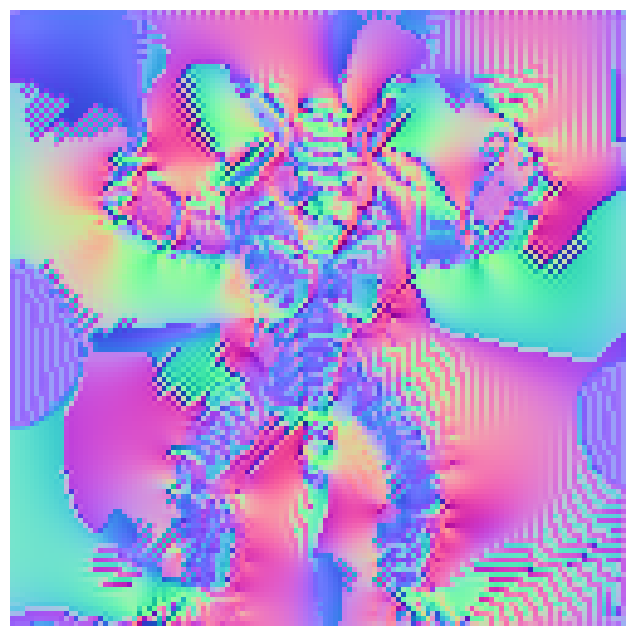

In [41]:
p_optimized = p_param.detach().cpu().numpy().reshape(height, width)  # (H,W)
q_optimized = q_param.detach().cpu().numpy().reshape(height, width)  # (H,W)


p_in = p_optimized[1:-1, 1:-1]  # (h_in, w_in)
q_in = q_optimized[1:-1, 1:-1]  # (h_in, w_in)

# (nx, ny, nz) = (p_in, q_in, 1.0)
# shape = (h_in, w_in, 3)
nxny = np.stack([p_in, q_in], axis=-1)  # (h_in, w_in, 2)
ones = np.ones((p_in.shape[0], p_in.shape[1], 1), dtype=p_in.dtype)
normal_map = np.concatenate([nxny, ones], axis=-1)  # (h_in, w_in, 3)
lengths = np.linalg.norm(normal_map, axis=-1, keepdims=True)  # shape (h_in, w_in, 1)
normal_map /= lengths
normal_map = normal_map.astype(np.float32)

normal_img = 0.5 * (normal_map + 1.0)
normal_img = np.clip(normal_img, 0.0, 1.0)  # shape (h_in, w_in, 3)

plt.figure(figsize=(8,8))
plt.imshow(normal_img, origin='lower')
plt.axis("off")
plt.show()

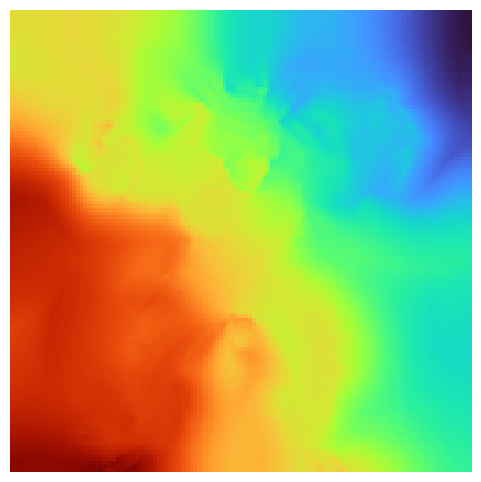

In [42]:
fx =  p_in.reshape((height-2, width-2))   # = ∂z/∂x
fy =  q_in.reshape((height-2, width-2))   # = ∂z/∂y

z_inner = np.real(frankotchellappa(fx, fy))

depth_map_est = np.zeros((height, width))
depth_map_est = -z_inner

plt.figure(figsize=(6,6))
plt.imshow(depth_map_est, cmap='turbo', origin='lower')
plt.axis('off')
#plt.colorbar()
plt.show()

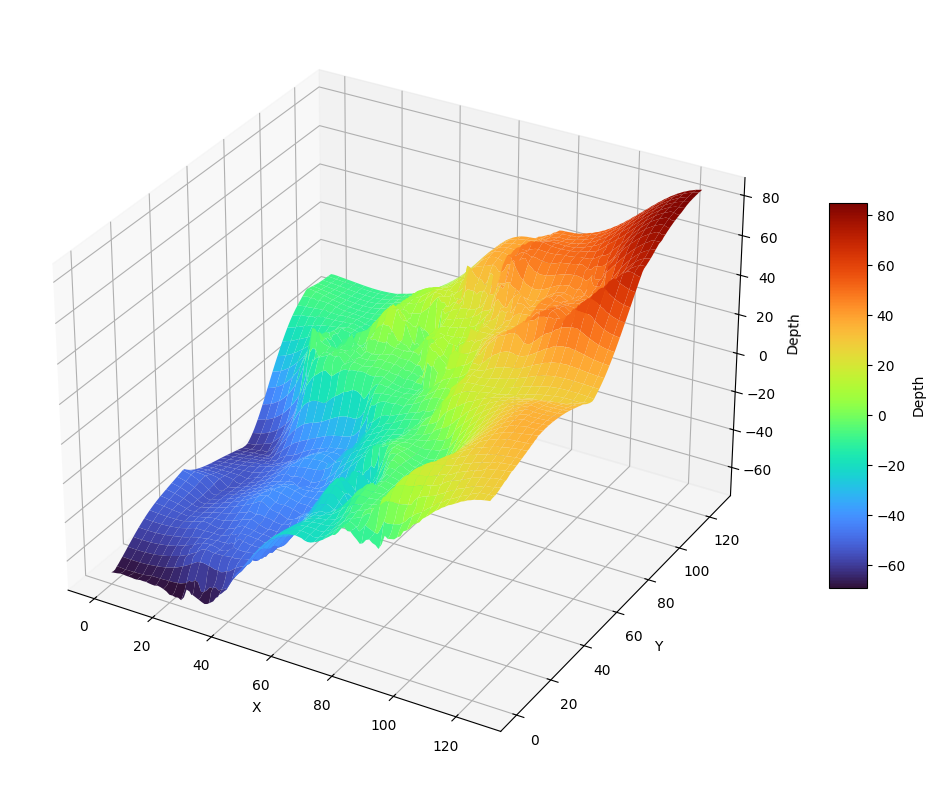

In [43]:
# Create a meshgrid for the x and y coordinates
x = np.linspace(0, depth_map_est.shape[1] - 1, depth_map_est.shape[1])
y = np.linspace(0, depth_map_est.shape[0] - 1, depth_map_est.shape[0])
x, y = np.meshgrid(x, y)

plt.figure(figsize=(10, 8))
plt.axes(projection='3d')
surf = plt.gca().plot_surface(x, y, -depth_map_est, cmap='turbo', edgecolor='none')

plt.colorbar(surf, shrink=0.5, aspect=10, label='Depth')
#plt.gca().set_zlim(-20, 20)
plt.xlabel("X")
plt.ylabel("Y")
plt.gca().set_zlabel("Depth")

plt.tight_layout()
plt.show()

In [44]:
# Create an interactive 3D surface plot using Plotly
fig = go.Figure(data=[go.Surface(z=-depth_map_est, x=x, y=y, colorscale='Turbo')])

# Adjust layout
fig.update_layout(scene=dict(xaxis_title='X',
                             yaxis_title='Y',
                             zaxis_title='Depth',
                             zaxis=dict(range=[-60, 60])),
                  autosize=True)

fig.show()

In [45]:
# def depth_map_to_obj(depth_map, filename, pixel_pitch=1.0):
#     """
#     depth_map : numpy array of shape (height, width)
#     filename  : Path to the output OBJ file
#     pixel_pitch: Spacing between pixels (scale in the world coordinate system)
#     """
#     height, width = depth_map.shape
#     vertices = []
#     faces = []
    
#     # Generate vertices for each pixel (x: column direction, y: row direction, z: depth value)
#     for i in range(height):
#         for j in range(width):
#             x = j * pixel_pitch
#             y = i * pixel_pitch
#             z = depth_map[i, j]
#             vertices.append((x, y, z))
    
#     # Generate faces: Treat each adjacent pixel region as one quadrilateral,
#     # then split it into two triangles to define the faces
#     for i in range(height - 1):
#         for j in range(width - 1):
#             # Since OBJ is 1-indexed, add +1 to the vertex indices
#             v1 = i * width + j + 1
#             v2 = i * width + (j + 1) + 1
#             v3 = (i + 1) * width + (j + 1) + 1
#             v4 = (i + 1) * width + j + 1
#             faces.append((v1, v2, v3))
#             faces.append((v1, v3, v4))
    
#     # Write to the OBJ file
#     with open(filename, 'w') as f:
#         # Write vertex information
#         for v in vertices:
#             f.write("v {} {} {}\n".format(v[0], v[1], v[2]))
#         # Write face information
#         for face in faces:
#             f.write("f {} {} {}\n".format(face[0], face[1], face[2]))

# # Save the OBJ file
# save_path = os.path.join(workspace_path, f"DATA/depth-to-obj/analysis-by-synthesis_{sim_params['obj_name']}.obj")

# #Use depth_map_est_gt_cropped or depth_map_est
# depth_map_to_obj(depth_map_est, save_path, pixel_pitch=1.0)
# print(f"OBJ file saved as {save_path}")

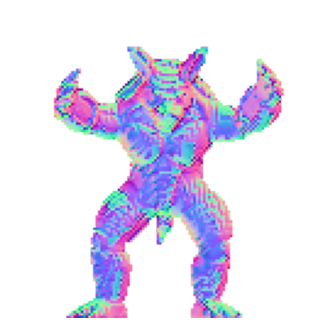

In [46]:
mask_in = mask2d[1:-1, 1:-1].astype(bool)
alpha = (~mask_in).astype(np.float32)
normal_rgba = np.dstack([normal_img, alpha])

plt.figure(figsize=(4,4))
plt.imshow(normal_rgba, origin="lower")
plt.axis("off")
plt.show()

In [47]:
mask_in = mask2d[1:-1, 1:-1].astype(bool)
valid = ~mask_in

def masked_nan(x, valid):
    x = x.astype(np.float32).copy()
    x[~valid] = np.nan
    return x


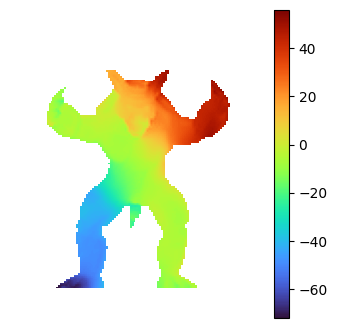

In [48]:
fx = p_in.reshape((height-2, width-2))
fy = q_in.reshape((height-2, width-2))

z_inner = np.real(frankotchellappa(fx, fy))  # (h-2, w-2)
mask_in = mask2d[1:-1, 1:-1].astype(bool)  # True=不要
valid = ~mask_in

z_vis = z_inner.copy().astype(np.float32)
z_vis[~valid] = np.nan
plt.figure(figsize=(4, 4))
plt.imshow(z_vis, origin='lower', cmap='turbo')
plt.axis("off")
plt.colorbar()
plt.show()

In [49]:
# def depth_map_to_obj_mask_faces_only(depth_map, valid_mask, filename, pixel_pitch=1.0):
#     """
#     depth_map : (H, W)
#     valid_mask: (H, W) bool, True=残す（この領域だけ面を作る）
#     """
#     height, width = depth_map.shape
#     assert valid_mask.shape == (height, width)

#     vertices = []
#     faces = []

#     # vertices: 全画素（元と同じ）
#     for i in range(height):
#         for j in range(width):
#             x = j * pixel_pitch
#             y = i * pixel_pitch
#             z = depth_map[i, j]
#             vertices.append((x, y, z))

#     # faces: マスクで間引く（セル4頂点が全部validのときだけ）
#     for i in range(height - 1):
#         for j in range(width - 1):
#             if not (valid_mask[i, j] and valid_mask[i, j+1] and valid_mask[i+1, j+1] and valid_mask[i+1, j]):
#                 continue

#             v1 = i * width + j + 1
#             v2 = i * width + (j + 1) + 1
#             v3 = (i + 1) * width + (j + 1) + 1
#             v4 = (i + 1) * width + j + 1
#             faces.append((v1, v2, v3))
#             faces.append((v1, v3, v4))

#     with open(filename, 'w') as f:
#         for v in vertices:
#             f.write("v {} {} {}\n".format(v[0], v[1], v[2]))
#         for face in faces:
#             f.write("f {} {} {}\n".format(face[0], face[1], face[2]))

#     print("OBJ saved:", filename, " #V:", len(vertices), " #F:", len(faces))

# import time
# t = time.strftime("%Y%m%d")
# # save_path = workspace_path + f"/results/main-sfl-{sim_params['obj_name']}_{t}_mask.obj"
# save_path = os.path.join(workspace_path, f"DATA/depth-to-obj/analysis-by-synthesis_{sim_params['obj_name']}.obj")

# valid_mask = ~(mask2d[1:-1, 1:-1].astype(bool))
# depth_map_to_obj_mask_faces_only(z_inner, valid_mask, save_path, pixel_pitch=1.0)
